# Case Study 4 — Adaptive Anomaly Detection: Replacing Static Alert Thresholds for Payment Health

**Priority:** ★★★ Must-visit · **Reference:** Case Study 4 — *Razorpay: Replacing Static Alert Thresholds with Adaptive Real-Time Anomaly Detection* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Payments Operations, Merchant Success, Risk / Fraud Operations, CTO office
**Data:** ⚠️ **SYNTHETIC** (D-4-01). Razorpay's event streams are private. All figures are a calibrated simulation, not Razorpay's.
**Reproducibility:** seed = 42 · run with `python -m nbconvert --to notebook --execute --inplace cs04_adaptive_anomaly_alerts.ipynb`

## 0. Executive Summary for Business

*(Synthetic data calibrated to Razorpay's documented problem; written after the analysis.)*

- **The problem:** fixed alarm lines ("success rate below 65%") ignore that payments naturally dip every night and on festive days. In our 48 monitored merchant × gateway lines they produced **58 false alerts a day** and still **missed 29% of real incidents**.
- **What we built:** a calendar-aware "normal" for every line, time slot and type of day (learnt from the last 14 days, with a festive adjustment learnt from Dussehra and applied to Diwali). It is scored with overdispersion-corrected statistics, plus a CUSUM chart for slow drifts.
- **Result on 4 untouched weeks:** **false alerts fell 90%** (58 → 6 a day; exact test p < 10⁻¹⁰⁰), matching Razorpay's documented ">90%". **Recall rose from 71% to 93%** (McNemar p = 0.03). Every gateway outage and latency spike was caught. Median detection is 10 minutes vs 5, a statistically insignificant delay (p = 0.14).
- **₹ impact:** analyst triage cost falls about **88%**, and revenue lost during incidents falls about 19% (faster catches of merchant-specific failures). Total cost falls **≈ 27%: ≈ ₹6.2 lakh per 28 days for 48 lines, or ≈ ₹17 crore a year per 1,000 lines** (range ₹11–26 crore).
- **What did not work:** an off-the-shelf Isolation Forest, given the same alerting volume, produced 40× more alert tickets. Unsupervised ML without a calendar-aware baseline just relearns the noise.
- **I recommend:** retire static thresholds for adaptive baselines with an explicit alert budget (≤ 10 false alerts a day), add gateway-level pooling to reach sub-minute detection, and group alerts by root cause.

## 1. The Problem in Simple English

A payment gateway watches thousands of "health lines": the success rate, speed and volume of payments for every merchant on every bank connection. When one breaks, the operations team must know **within minutes**, before a merchant loses an evening of Diwali sales.

The old way was **fixed alarms**: "page someone if success rate drops below 65%" or "if latency goes above 2.5 seconds". Fixed alarms fail in two directions at once:

- **They cry wolf.** At 3 a.m., banks run maintenance and success rates dip *every night*. During a festive sale, traffic triples. A fixed line set for a Tuesday afternoon fires constantly at those times. Analysts get hundreds of alerts and start ignoring them (**alert fatigue**). The reference file notes this cost Razorpay about **$500K a year**.
- **They sleep through real problems.** A large merchant whose success rate falls from 92% to 80% is in real trouble, yet never crosses a 65% line. A slow, creeping degradation never trips anything.

The better question is: **"Is this number abnormal *for this merchant, on this gateway, at this time of day, on this kind of day*?"** That is an *adaptive baseline*. This notebook builds one, proves statistically that it beats fixed thresholds, and puts a ₹ value on the difference.

## 2. Reference from the Case File

### (a) What Razorpay actually did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Static thresholds could not scale to millions of merchants. They left blind spots, caused alert fatigue and cost about **$500K a year**." |
| Question | "For every merchant × gateway combination, is the current success rate, latency or velocity *abnormal given its own normal pattern* (time of day, day of week, holidays)?" |
| Data | "~5 billion events/day"; success rates, latency regressions, card testing, velocity abuse, gateway × merchant degradation |
| Approach | "Build **calendar-aware adaptive baselines** for each series"; complex event processing ("five declines then a success suggests card testing"); rules in a declarative DSL; "ML models can supply thresholds" |
| Statistics | "Seasonal / calendar baselining (day-of-week, time-of-day, holiday effects). The exact statistical method is ND." |
| Metrics | "Detection latency, false-positive volume, cost, uptime" |
| Impact | "Detection in under 30 seconds (previously 1–2 minutes)"; "About **80%** cost reduction"; "**>90%** reduction in false positives"; "99.99% uptime" |
| Tools | Amazon MSK (Kafka), Apache Flink, ClickHouse (baselines), Aurora MySQL + Debezium CDC |

**Source:** AWS Big Data Blog, "How Razorpay built real-time anomaly detection with Amazon MSK", 13 Jul 2026 — https://aws.amazon.com/blogs/big-data/how-razorpay-built-real-time-anomaly-detection-with-amazon-msk/

### (b) What *we* simulate and add — *our professional approach*

| Item | Our choice |
|---|---|
| Data | 48 merchant × gateway series, 5-minute windows, 6 weeks (29 Sep – 9 Nov 2025, spanning Dussehra and Diwali); 41 labelled incidents of 5 types |
| Baseline (since the method is "ND") | Trailing-14-day, slot-of-day pooled success rate per series, a festive adjustment learnt from Dussehra and applied to Diwali, and **quasi-binomial z-scores** (overdispersion-corrected) |
| Detectors compared | (1) static thresholds (today); (2) a non-seasonal p-chart; (3) the adaptive baseline; (4) adaptive + **CUSUM** for slow drifts; (5) an **Isolation Forest** at a fixed alert budget |
| Statistics added | Kruskal–Wallis seasonality tests, Pearson overdispersion test, Ljung–Box autocorrelation, multiple-testing alert budget, McNemar, exact Poisson rate-ratio test, Wilcoxon signed-rank, Wilson and bootstrap CIs |
| Honest evaluation | Thresholds chosen on a **calibration week** using analyst capacity only (no incident labels), then evaluated on **4 untouched weeks** |

### (c) How the industry uses this

Every Indian payment gateway and bank runs some form of this: Razorpay (documented above), Cashfree's SR-based routing thresholds (Case 2), Juspay's downtime detection (Case 1), and NPCI-level UPI health dashboards. The same machinery also monitors **fraud velocity** (card testing), **loan-disbursal pipelines**, and **model drift** (Case 11's PSI is the slow, monthly cousin of this real-time version).

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| **Business** | Should we retire static alert thresholds for an adaptive system, and what is it worth? |
| **Analytical 1** | Do success rate and volume follow time-of-day / day-of-week / festive patterns strong enough to break fixed thresholds? |
| **Analytical 2** | Is the variation in 5-minute success counts larger than pure binomial chance (overdispersion), and is it autocorrelated? |
| **Analytical 3** | On held-out weeks, does the adaptive detector find at least as many real incidents, with far fewer false alerts and acceptable delay? |

**Hypotheses** (fixed before evaluation):
- **H1 (seasonality):** H0: success rate has the same distribution in every hour of the day. Kruskal–Wallis.
- **H2 (overdispersion):** H0: dispersion φ = 1 (pure binomial). Pearson χ² test.
- **H3 (autocorrelation):** H0: no autocorrelation in standardised residuals up to lag 12 (1 hour). Ljung–Box.
- **H4 (detection):** H0: the adaptive and static detectors catch the same incidents. Exact McNemar.
- **H5 (false alerts):** H0: equal false-alert rates. Exact conditional Poisson (binomial) rate-ratio test.
- **H6 (speed):** H0: equal detection latency on incidents both catch. Wilcoxon signed-rank.

**Primary metric:** false-alert episodes per day (alert fatigue). **Co-primary:** incident recall (share of real incidents detected).
**Guardrails:** median detection latency ≤ 15 minutes; recall per incident type.
**Unit:** incident (for recall/latency); alert episode (for false alerts; consecutive alert windows on one series = one episode).
**Decision rule:** adopt the adaptive detector if false alerts fall by ≥ 50% (H5 rejected), recall is **not worse by more than 10 pp** (non-inferiority), and median latency is ≤ 15 minutes.

In [1]:
import sys, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import expit, logit
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from sklearn.ensemble import IsolationForest

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore", category=FutureWarning); warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public payment-health time series with labelled incidents (UCI, data.gov.in, GitHub) | **None.** NPCI publishes monthly UPI decline statistics only. Public anomaly benchmarks (e.g., the Numenta NAB corpus on GitHub) are generic server/IoT series, not payments, and have no binomial structure (attempts/successes). |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | Synthetic data with ground-truth incidents. The ground truth is what makes detector *recall* measurable, which is rarely possible with real data, where unlabelled incidents are the norm (D-4-01). |

### 4.2 Generator (synthetic data) — clearly marked section

In [2]:
%%writefile data/generate_cs04.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 4 (Razorpay-style adaptive anomaly detection)
==================================================================================
THIS DATA IS SYNTHETIC. Razorpay's event streams are private, and no public dataset
has merchant x gateway payment-health time series with labelled incidents.

We simulate 48 series (16 merchants x 3 gateways) in 5-minute windows for 6 weeks
(29 Sep - 9 Nov 2025: Dussehra 1-2 Oct, Diwali week 18-21 Oct) with:
  * time-of-day and day-of-week volume/SR patterns, festive load
  * overdispersion and autocorrelation (an AR(1) wobble on the log-odds of success)
  * ~40 labelled incidents of 5 types: gateway outage, merchant integration failure,
    latency spike, card-testing burst, slow degradation
Calibration anchors (reference file, Case Study 4): metrics monitored = success rate,
latency regressions, card testing, velocity abuse, gateway x merchant degradation;
baselines must be calendar-aware (time of day, day of week, holidays).
All effect sizes are our assumptions (decision.md D-4-02 ... D-4-04).

Outputs: data/cs04/payment_health_5min.csv.gz and data/cs04/incidents.csv
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit, logit

SEED = 42
START, DAYS, SLOT_MIN = pd.Timestamp("2025-09-29"), 42, 5
MERCHANTS, GATEWAYS = [f"M{i:02d}" for i in range(1, 17)], ["GW_A", "GW_B", "GW_C"]
FESTIVE = {"2025-10-01": 1.3, "2025-10-02": 1.4, "2025-10-18": 1.8, "2025-10-19": 1.6, "2025-10-20": 1.7, "2025-10-21": 1.5}
HOUR_VOL = np.array([0.35, 0.22, 0.15, 0.12, 0.12, 0.18, 0.35, 0.60, 0.85, 1.00, 1.10, 1.20,
                     1.30, 1.25, 1.10, 1.05, 1.05, 1.10, 1.25, 1.45, 1.60, 1.65, 1.40, 0.85])
HOUR_SR = np.where(np.arange(24) < 5, -0.30, np.where((np.arange(24) >= 19) & (np.arange(24) < 23), -0.06, 0.0))


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    ts = pd.date_range(START, periods=DAYS * 24 * 60 // SLOT_MIN, freq=f"{SLOT_MIN}min")
    T = len(ts); hours = ts.hour.to_numpy(); day = ts.strftime("%Y-%m-%d")
    fest = pd.Series(day).map(FESTIVE).fillna(1.0).to_numpy()
    weekend = np.asarray(ts.dayofweek >= 5)
    size = np.exp(rng.normal(np.log(14), 0.6, len(MERCHANTS)))                 # merchant size (attempts / 5 min at peak)
    share = rng.dirichlet([4, 3, 2], len(MERCHANTS))                          # gateway split per merchant
    frames, s_id = [], 0
    base_sr = {}
    for mi, m in enumerate(MERCHANTS):
        for gi, g in enumerate(GATEWAYS):
            lam = size[mi] * share[mi, gi] * 3 * HOUR_VOL[hours] * fest * np.where(weekend, 1.1, 1.0)
            b = logit(rng.uniform(0.80, 0.90))
            base_sr[(m, g)] = b
            ar = np.zeros(T); eps = rng.normal(0, 0.06, T)                    # AR(1) wobble -> overdispersion + autocorrelation
            for t in range(1, T):
                ar[t] = 0.9 * ar[t - 1] + eps[t]
            z = b + HOUR_SR[hours] - 0.15 * (fest > 1) + ar
            lat = np.exp(np.log(900 + 150 * gi) + 0.25 * np.log(fest) + 0.12 * (HOUR_VOL[hours] > 1.3) + rng.normal(0, 0.10, T))
            frames.append(dict(series=s_id, merchant=m, gateway=g, lam=lam, z=z, lat=lat))
            s_id += 1
    S = len(frames)
    Z = np.stack([f["z"] for f in frames]); LAM = np.stack([f["lam"] for f in frames]); LAT = np.stack([f["lat"] for f in frames])

    # ---- incidents (ground truth) ----
    inc = []
    def add(kind, series_idx, start_slot, dur_slots, **kw):
        inc.append(dict(kind=kind, series=list(series_idx), start=int(start_slot), dur=int(dur_slots), **kw))
    slots_per_day = 288
    def rand_start(lo_day=3, hi_day=DAYS - 1):
        return rng.integers(lo_day * slots_per_day, hi_day * slots_per_day)
    for _ in range(8):   # gateway outage: every merchant on that gateway
        g = rng.integers(0, 3); add("gateway_outage", [i for i in range(S) if i % 3 == g], rand_start(), rng.integers(3, 25), drop=rng.uniform(1.5, 3.0))
    for _ in range(10):  # merchant integration failure on one gateway
        add("merchant_failure", [rng.integers(0, S)], rand_start(), rng.integers(6, 48), drop=rng.uniform(1.2, 2.5))
    for _ in range(8):   # latency spike
        add("latency_spike", [rng.integers(0, S)], rand_start(), rng.integers(3, 12), mult=rng.uniform(2.0, 3.5))
    for _ in range(8):   # card testing: attempt burst, most fail
        add("card_testing", [rng.integers(0, S)], rand_start(), rng.integers(2, 8), burst=rng.uniform(4, 8))
    for _ in range(6):   # slow degradation: small drop for hours
        add("slow_degradation", [rng.integers(0, S)], rand_start(), rng.integers(36, 72), drop=rng.uniform(0.35, 0.6))
    # one guaranteed outage during Diwali evening peak (the hardest time for static rules)
    add("gateway_outage", [i for i in range(S) if i % 3 == 1], 20 * slots_per_day + 20 * 12, 18, drop=2.2)
    extra_att = np.zeros_like(LAM)
    for e in inc:
        sl = slice(e["start"], min(e["start"] + e["dur"], T))
        for s in e["series"]:
            if e["kind"] in ("gateway_outage", "merchant_failure", "slow_degradation"):
                Z[s, sl] -= e["drop"]
            elif e["kind"] == "latency_spike":
                LAT[s, sl] *= e["mult"]
            elif e["kind"] == "card_testing":
                extra_att[s, sl] = LAM[s, sl] * e["burst"]

    att = rng.poisson(LAM)
    succ = rng.binomial(att, expit(Z))
    bot = rng.poisson(extra_att)                                                  # card-testing attempts: ~5% succeed
    att = att + bot; succ = succ + rng.binomial(bot, 0.05)
    lat_p95 = np.round(LAT * np.exp(rng.normal(0, 0.05, LAT.shape)))
    lat_p95 = np.where(att == 0, np.nan, lat_p95)

    rows = pd.DataFrame({
        "timestamp": np.tile(ts.values, S),
        "merchant_id": np.repeat([f["merchant"] for f in frames], T),
        "gateway": np.repeat([f["gateway"] for f in frames], T),
        "attempts": att.ravel(), "successes": succ.ravel(), "latency_p95_ms": lat_p95.ravel()})
    # ---- data-quality issue: a collector restart duplicated 2 hours of windows for GW_C on 24 Oct ----
    dup = rows[(rows.gateway == "GW_C") & rows.timestamp.between("2025-10-24 10:00", "2025-10-24 11:55")]
    rows = pd.concat([rows, dup], ignore_index=True).sort_values(["merchant_id", "gateway", "timestamp"], kind="stable").reset_index(drop=True)
    inc_df = pd.DataFrame([{"incident_id": i + 1, "type": e["kind"],
                            "start": ts[e["start"]], "end": ts[min(e["start"] + e["dur"], T) - 1] + pd.Timedelta(minutes=SLOT_MIN),
                            "series": ";".join(f"{frames[s]['merchant']}|{frames[s]['gateway']}" for s in e["series"])}
                           for i, e in enumerate(inc)])
    return rows, inc_df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs04"), exist_ok=True)
    d, i = generate()
    d.to_csv(os.path.join(here, "cs04", "payment_health_5min.csv.gz"), index=False)
    i.to_csv(os.path.join(here, "cs04", "incidents.csv"), index=False)
    print(len(d), "rows;", len(i), "incidents; overall SR", round(d.successes.sum() / d.attempts.sum(), 4))

Overwriting data/generate_cs04.py


In [3]:
import os
os.makedirs("data/cs04", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs04 as gen; importlib.reload(gen)
raw, incidents = gen.generate(seed=SEED)
raw.to_csv("data/cs04/payment_health_5min.csv.gz", index=False); incidents.to_csv("data/cs04/incidents.csv", index=False)
print(f"{len(raw):,} rows (series × 5-min windows) | {len(incidents)} labelled incidents")
incidents.groupby("type").size().rename("incidents").to_frame()

580,992 rows (series × 5-min windows) | 41 labelled incidents


,incidents
type,
card_testing,8
gateway_outage,9
latency_spike,8
merchant_failure,10
slow_degradation,6


| Parameter | Value | Basis |
|---|---|---|
| Series | 16 merchants × 3 gateways = 48 | Our assumption (enough to show the statistics; Razorpay has millions) |
| Volume | ≈ 15 attempts per series per 5 minutes; hour-of-day profile; weekend ×1.1; festive ×1.3–1.8 | Our assumption (Indian e-commerce rhythm) |
| Success rate | 80–90% per series; night −0.30 log-odds; festive −0.15; AR(1) wobble (ρ = 0.9, σ = 0.06) | Our assumption. The wobble creates the overdispersion and autocorrelation that real series have |
| Latency p95 | ≈ 0.9–1.2 s by gateway, rising with load | Our assumption |
| Incidents | 9 gateway outages, 10 merchant failures, 8 latency spikes, 8 card-testing bursts, 6 slow degradations | Types are **documented** ("success rates, latency regressions, card testing, velocity abuse, gateway × merchant degradation"); counts and sizes are ours |
| DQ defect | A collector restart re-sent 2 hours of GW_C windows on 24 Oct (duplicates) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("timestamp", "Start of the 5-minute window (IST)", "29 Sep – 9 Nov 2025"),
    ("merchant_id", "Merchant", "M01–M16"),
    ("gateway", "Payment gateway / bank connection", "GW_A, GW_B, GW_C"),
    ("attempts", "Payment attempts in the window", "≥ 0"),
    ("successes", "Successful payments in the window", "0 … attempts"),
    ("latency_p95_ms", "95th-percentile gateway latency (ms); blank when attempts = 0", "> 0"),
    ("incidents.csv", "Ground truth: incident id, type, start, end, affected series", "41 incidents"),
], columns=["field", "meaning", "range"])
dd.to_csv("data/cs04/data_dictionary.csv", index=False); dd

,field,meaning,range
0,timestamp,Start of the 5-minute window (IST),29 Sep – 9 Nov 2025
1,merchant_id,Merchant,M01–M16
2,gateway,Payment gateway / bank connection,"GW_A, GW_B, GW_C"
3,attempts,Payment attempts in the window,≥ 0
4,successes,Successful payments in the window,0 … attempts
5,latency_p95_ms,95th-percentile gateway latency (ms); blank wh...,> 0
6,incidents.csv,"Ground truth: incident id, type, start, end, a...",41 incidents


## 5. Data Quality Checks

**Business view:** a monitoring system that double-counts data will raise false alarms of its own making. We check the time grid, duplicates, impossible values and gaps before building any baseline.

In [5]:
df = pd.read_csv("data/cs04/payment_health_5min.csv.gz", parse_dates=["timestamp"])
grid = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq="5min")
checks = {
    "duplicate (timestamp, merchant, gateway) rows": int(df.duplicated(["timestamp", "merchant_id", "gateway"]).sum()),
    "successes > attempts": int((df.successes > df.attempts).sum()),
    "negative counts": int(((df.attempts < 0) | (df.successes < 0)).sum()),
    "windows with attempts = 0": int((df.attempts == 0).sum()),
    "latency blank when attempts > 0": int((df.latency_p95_ms.isna() & (df.attempts > 0)).sum()),
    "missing windows in grid": int(len(grid) * 48 - df.drop_duplicates(["timestamp", "merchant_id", "gateway"]).shape[0]),
}
print(pd.Series(checks, name="rows").to_string())
dups = df[df.duplicated(["timestamp", "merchant_id", "gateway"], keep=False)]
print("\nDuplicates are concentrated in:", dups.groupby(["gateway", dups.timestamp.dt.date]).size().to_dict())
identical = dups.groupby(["timestamp", "merchant_id", "gateway"]).nunique().max().max() == 1
print("Duplicate copies identical?", identical)

duplicate (timestamp, merchant, gateway) rows      384
successes > attempts                                 0
negative counts                                      0
windows with attempts = 0                        24252
latency blank when attempts > 0                      0
missing windows in grid                              0



Duplicates are concentrated in: {('GW_C', datetime.date(2025, 10, 24)): 768}
Duplicate copies identical? True


In [6]:
df = df.drop_duplicates(["timestamp", "merchant_id", "gateway"]).sort_values(["merchant_id", "gateway", "timestamp"]).reset_index(drop=True)
df["key"] = df.merchant_id + "|" + df.gateway
dq = pd.DataFrame([
    ("Duplicate windows (collector restart, GW_C, 24 Oct)", checks["duplicate (timestamp, merchant, gateway) rows"], "Drop exact duplicates", "Would double attempts and successes in those windows: a fake volume spike and z-scores √2 too large"),
    ("attempts = 0 windows", checks["windows with attempts = 0"], "Keep; SR undefined, latency blank", "Genuine quiet night windows; excluded from SR z-scores (need ≥ 3 attempts)"),
    ("Card-testing attempt spikes (up to ~200 per window)", "—", "Keep", "Outliers ARE the signal we want to detect; never winsorise monitoring data"),
], columns=["issue", "rows", "treatment", "reason"])
print(f"Clean rows: {len(df):,} = 48 series × {len(grid):,} windows")
dq

Clean rows: 580,608 = 48 series × 12,096 windows


,issue,rows,treatment,reason
0,"Duplicate windows (collector restart, GW_C, 24...",384,Drop exact duplicates,Would double attempts and successes in those w...
1,attempts = 0 windows,24252,"Keep; SR undefined, latency blank",Genuine quiet night windows; excluded from SR ...
2,Card-testing attempt spikes (up to ~200 per wi...,—,Keep,Outliers ARE the signal we want to detect; nev...


**Observation:** the collector restart re-sent **384 windows** (16 GW_C series × 24 windows on 24 Oct), all byte-identical. Left in, each would look like a sudden **doubling of volume**, which is precisely the signature of a card-testing attack. **Monitoring pipelines must de-duplicate on (series, window) before scoring**, or they generate their own incidents. The 24,252 zero-attempt windows are genuine quiet periods (mostly 1–5 a.m. on small merchants) and are kept. Left in, each would look like a sudden **doubling of volume**: precisely the signature of a card-testing attack. **Monitoring pipelines must de-duplicate on (series, window) before scoring**, or they generate their own incidents.

## 6. Exploratory Data Analysis

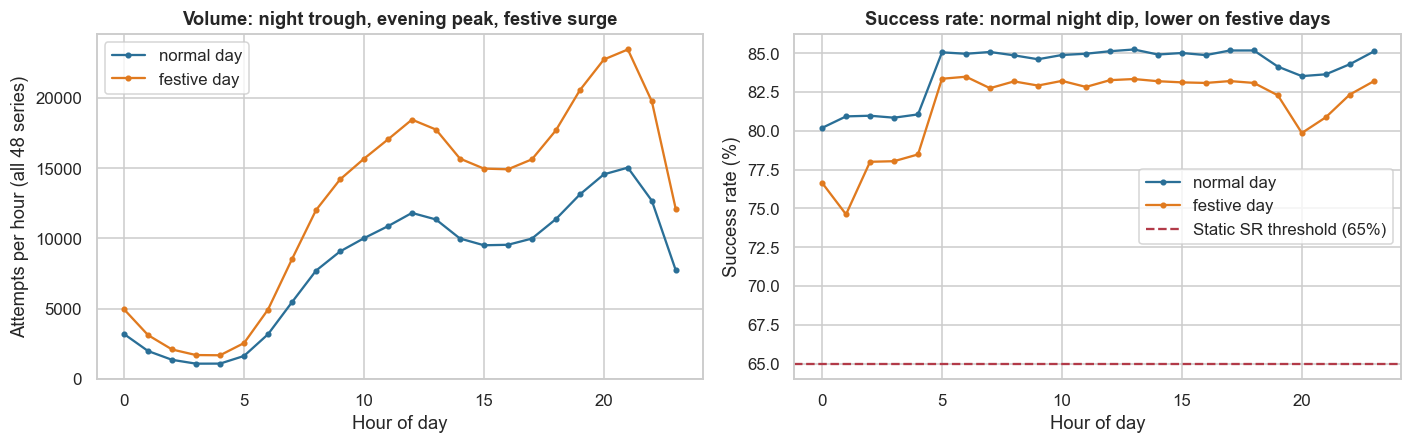

In [7]:
keys = sorted(df.key.unique()); ts = pd.DatetimeIndex(np.sort(df.timestamp.unique())); S, T = len(keys), len(ts)
piv = lambda c: df.pivot(index="key", columns="timestamp", values=c).reindex(keys).to_numpy(float)
A, Y, L = piv("attempts"), piv("successes"), piv("latency_p95_ms")
D = T // 288; dayi = np.arange(T) // 288; hour = ts.hour.to_numpy()
FEST = set(gen.FESTIVE); fest = np.isin(ts.strftime("%Y-%m-%d"), list(FEST))
hr = pd.DataFrame({"hour": hour, "att": A.sum(0), "succ": Y.sum(0), "fest": fest})
prof = hr.groupby(["fest", "hour"]).agg(att=("att", "mean"), sr=("succ", "sum")).assign(sr=lambda x: x.sr / hr.groupby(["fest", "hour"]).att.sum())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for f, c, lab in [(False, "#2a6f97", "normal day"), (True, "#e07a1f", "festive day")]:
    p_ = prof.loc[f]; axes[0].plot(p_.index, p_.att * 12, "o-", color=c, ms=3, label=lab); axes[1].plot(p_.index, p_.sr * 100, "o-", color=c, ms=3, label=lab)
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Attempts per hour (all 48 series)"); axes[0].set_title("Volume: night trough, evening peak, festive surge"); axes[0].legend()
axes[1].axhline(65, color="#b23a48", ls="--", label="Static SR threshold (65%)"); axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("Success rate (%)")
axes[1].set_title("Success rate: normal night dip, lower on festive days"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** volume swings about **10×** between 3 a.m. and 9 p.m., and festive days add another 30–80%. Success rate dips every night (bank maintenance) and on festive days. Any single fixed threshold is wrong for most hours of the week: either too tight at night or too loose at peak.

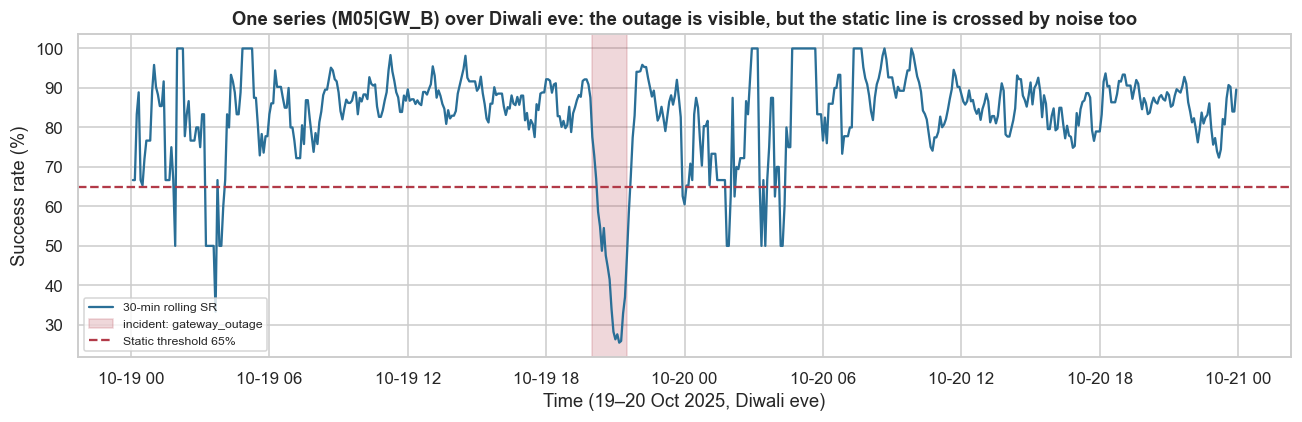

In [8]:
ex = keys.index("M05|GW_B") if "M05|GW_B" in keys else 0
win = slice(20 * 288, 22 * 288)
sr_ex = np.divide(Y[ex, win], A[ex, win], out=np.full(win.stop - win.start, np.nan), where=A[ex, win] > 0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ts[win], pd.Series(sr_ex).rolling(6, min_periods=1).mean() * 100, color="#2a6f97", label="30-min rolling SR")
for _, e in incidents[incidents.series.str.contains(keys[ex], regex=False)].iterrows():
    if ts[win][0] <= e.start <= ts[win][-1]:
        ax.axvspan(e.start, e.end, color="#b23a48", alpha=0.2, label=f"incident: {e.type}")
ax.axhline(65, color="#b23a48", ls="--", label="Static threshold 65%")
ax.set_xlabel("Time (19–20 Oct 2025, Diwali eve)"); ax.set_ylabel("Success rate (%)"); ax.set_title(f"One series ({keys[ex]}) over Diwali eve: the outage is visible, but the static line is crossed by noise too")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

**Takeaway:** a single 5-minute window holds only about 5–30 payments, so the raw success rate jumps around by ±10 points from pure chance. Incidents are real, but they sit inside a noisy, seasonal signal. That is why the detector must reason in **counts and probabilities** (how surprising are *k* successes out of *n* attempts?), not raw percentages.

## 7. Statistical Analysis (core section)

Each step: **(a) why, (b) assumptions, (c) result + effect size + CI, (d) power / sample size, (e) multiple testing, (f) business meaning.** Period roles: days 1–7 warm-up (no baseline yet), **days 8–14 calibration week** (fit dispersion, choose thresholds), **days 15–42 hold-out evaluation (4 weeks)**.

### 7.1 Seasonality: Kruskal–Wallis tests

**(a) Why?** We want to know whether "normal" depends on the hour (and the day), which decides whether a single global threshold can ever work. Hourly success rates per series-day are bounded and skewed, so we use the rank-based **Kruskal–Wallis** test rather than ANOVA. **Effect size:** ε² (share of rank variance explained). **(b)** Independence of series-days is approximate; we read the effect size, not just the p-value.

In [9]:
hrows = pd.DataFrame({"series": np.repeat(np.arange(S), T), "day": np.tile(dayi, S), "hour": np.tile(hour, S),
                      "dow": np.tile(ts.dayofweek, S), "fest": np.tile(fest, S), "att": A.ravel(), "succ": Y.ravel()})
hh = hrows.groupby(["series", "day", "hour"]).agg(att=("att", "sum"), succ=("succ", "sum"), fest=("fest", "first"), dow=("dow", "first")).reset_index()
hh = hh[hh.att >= 20].assign(sr=lambda x: x.succ / x.att)
def kw(groups):
    H, p = stats.kruskal(*groups); n = sum(map(len, groups)); k = len(groups)
    return H, p, (H - k + 1) / (n - k)
nonfest = hh[~hh.fest]
H1, p1, e1 = kw([g.sr.values for _, g in nonfest.groupby("hour")])
dv = hh.groupby(["series", "day"]).agg(att=("att", "sum"), dow=("dow", "first"), fest=("fest", "first")).reset_index()
H2, p2, e2 = kw([g.att.values for _, g in dv[~dv.fest].groupby("dow")])
print(f"SR by hour of day (non-festive): H = {H1:,.0f}, p = {p1:.2g}, epsilon² = {e1:.3f}")
print(f"Daily volume by day of week (non-festive): H = {H2:,.1f}, p = {p2:.2g}, epsilon² = {e2:.4f}")
fs, ns_ = hh[hh.fest], hh[~hh.fest]
lo_shift = logit(fs.succ.sum() / fs.att.sum()) - logit(ns_.succ.sum() / ns_.att.sum())
print(f"Festive vs normal SR: {fs.succ.sum() / fs.att.sum():.2%} vs {ns_.succ.sum() / ns_.att.sum():.2%} (log-odds shift {lo_shift:+.3f})")

SR by hour of day (non-festive): H = 1,933, p = 0, epsilon² = 0.051
Daily volume by day of week (non-festive): H = 10.0, p = 0.12, epsilon² = 0.0023
Festive vs normal SR: 82.32% vs 84.50% (log-odds shift -0.158)


**(c)/(f) Observation:** success rate differs strongly by hour of day (Kruskal–Wallis H = 1,933, p ≈ 0, **ε² = 0.05**). Hour alone explains about 5% of the rank variation in hourly success rates, a moderate effect, concentrated in the 00:00–05:00 bank-maintenance dip. Festive days run 2.2 points lower (82.3% vs 84.5%; log-odds −0.16). Daily volume by **day of week is *not* significantly different** (p = 0.12, ε² ≈ 0): the weekend uplift of about 10% is too small to prove with 6 weeks of data. **For the business:** the time-of-day and festive patterns are real and large enough to break any single threshold. A day-of-week adjustment adds little here, so we keep the baseline simple (slot-of-day + festive calendar).

### 7.2 Overdispersion: are 5-minute counts noisier than binomial chance?

**(a) Why?** A textbook p-chart assumes successes ~ Binomial(n, p): each window's spread is pure coin-flipping. Real payment series also have small, persistent wobbles (bank-side load, app releases), which make the spread larger. That is **overdispersion**. If we ignore it, every alarm threshold is too tight and false alerts explode.
**Test:** the Pearson statistic X² = Σ (y − n p̂)² / (n p̂ (1 − p̂)) over calibration-week windows, compared with χ²(df). **Dispersion φ̂ = X²/df.** φ = 1 means binomial; φ > 1 means overdispersed. We then use **quasi-binomial z-scores**: z = (y − n p̂)/√(φ̂ · n p̂(1 − p̂)).
**Baseline p̂ (the "adaptive" part):** for each series and each 5-minute slot of the day, the pooled success rate over the trailing 14 days (± 1 neighbouring slot, festive days excluded). On festive days, we add a log-odds shift *learnt from Dussehra* (1–2 Oct, calibration period) and apply it to Diwali. The same structure gives expected volume.

In [10]:
def build_baseline(A, Y, window_days=14):
    A3 = A.reshape(S, D, 288).copy(); Y3 = Y.reshape(S, D, 288).copy()
    day_dates = pd.date_range(ts[0].normalize(), periods=D, freq="D").strftime("%Y-%m-%d")
    fest_day = np.isin(day_dates, list(FEST))
    A3[:, fest_day] = 0; Y3[:, fest_day] = 0
    sm = lambda X: X + np.roll(X, 1, axis=2) + np.roll(X, -1, axis=2)       # pool ±1 neighbouring slot
    cA, cY = np.cumsum(sm(A3), axis=1), np.cumsum(sm(Y3), axis=1)
    nday = np.cumsum(~fest_day)
    pA, pY = np.full(A3.shape, np.nan), np.full(A3.shape, np.nan)
    for d_ in range(7, D):
        lo = max(0, d_ - window_days)
        sa = cA[:, d_ - 1] - (cA[:, lo - 1] if lo else 0); sy = cY[:, d_ - 1] - (cY[:, lo - 1] if lo else 0)
        nd = nday[d_ - 1] - (nday[lo - 1] if lo else 0)
        pA[:, d_] = sa / nd / 3; pY[:, d_] = sy / np.maximum(sa, 1)
    return np.clip(pY.reshape(S, T), 0.02, 0.99), pA.reshape(S, T)

p_hat, v_hat = build_baseline(A, Y)
dus = np.isin(ts.strftime("%Y-%m-%d"), ["2025-10-01", "2025-10-02"]); nbr = np.isin(ts.strftime("%Y-%m-%d"), ["2025-09-29", "2025-09-30", "2025-10-03", "2025-10-04"])
FEST_LO = logit(Y[:, dus].sum() / A[:, dus].sum()) - logit(Y[:, nbr].sum() / A[:, nbr].sum())
FEST_VOL = (A[:, dus].sum() / 2) / (A[:, nbr].sum() / 4)
p_adj = np.where(fest[None, :], expit(logit(p_hat) + FEST_LO), p_hat)
v_adj = np.where(fest[None, :], v_hat * FEST_VOL, v_hat)
calib = (dayi >= 7) & (dayi < 14); hold = dayi >= 14
m = calib[None, :] & (A >= 5) & ~np.isnan(p_adj)
pear = ((Y - A * p_adj) ** 2 / (A * p_adj * (1 - p_adj)))[m]
X2, dfree = pear.sum(), m.sum() - S
phi = X2 / dfree
p_disp = stats.chi2.sf(X2, dfree)
print(f"Festive adjustment learnt from Dussehra: SR log-odds {FEST_LO:+.3f}, volume ×{FEST_VOL:.2f}")
print(f"Pearson X² = {X2:,.0f} on {dfree:,} df -> dispersion phi = {phi:.3f}; p = {p_disp:.2g}")
z_sr = np.where((A >= 3) & ~np.isnan(p_adj), (Y - A * p_adj) / np.sqrt(phi * A * p_adj * (1 - p_adj)), 0.0)
z_vol = np.nan_to_num((A - v_adj) / np.sqrt(np.maximum(1.5 * v_adj, 1)))
# latency: robust slot-of-day median / MAD of log latency over the trailing 14 non-festive days, pooled with the
# neighbouring slots (3 x up to 14 values) and a MAD floor of 0.05 so a lucky quiet fortnight cannot make the band razor-thin
LL = np.log(L).reshape(S, D, 288); med = np.full(LL.shape, np.nan); mad = np.full(LL.shape, np.nan)
day_fest = np.isin(pd.date_range(ts[0].normalize(), periods=D, freq="D").strftime("%Y-%m-%d"), list(FEST))
LLm, LLp = np.roll(LL, 1, axis=2), np.roll(LL, -1, axis=2)
for d_ in range(7, D):
    idx = [j for j in range(max(0, d_ - 14), d_) if not day_fest[j]]
    w = np.concatenate([LL[:, idx], LLm[:, idx], LLp[:, idx]], axis=1)
    med[:, d_] = np.nanmedian(w, axis=1); mad[:, d_] = np.maximum(1.4826 * np.nanmedian(np.abs(w - med[:, d_][:, None]), axis=1), 0.05)
z_lat = np.nan_to_num(((LL - med) / mad).reshape(S, T), nan=0, posinf=0, neginf=0)
z_lat = np.where(fest[None, :], z_lat - np.nanmedian(z_lat[:, fest & (dayi < 14)]), z_lat)   # festive latency shift (learnt on Dussehra)

Festive adjustment learnt from Dussehra: SR log-odds -0.176, volume ×1.32
Pearson X² = 96,035 on 69,942 df -> dispersion phi = 1.373; p = 0


**(c)/(f) Observation:** the Pearson dispersion is **φ = 1.37** (p ≈ 0, so H0 φ = 1 is rejected). Five-minute success counts are about 37% more variable than coin-flipping alone. A textbook binomial alarm therefore uses error bars about 15% too narrow (√1.37 = 1.17). Over 13,824 tests a day, that is the difference between a manageable and an unmanageable alert stream. The festive shift learnt on Dussehra (−0.18 log-odds, volume ×1.32) closely matches the actual Diwali shift (−0.16; Section 7.1), so a calendar learnt from one festival transfers to the next.

### 7.3 Autocorrelation: Ljung–Box test on residuals

**(a) Why?** If one window is unusually low, is the next one likely to be low too? If so, (1) the windows are **not independent**, so the effective number of tests is smaller than it looks, and (2) a rule that waits for **two consecutive** low windows filters noise cheaply. **Ljung–Box** tests whether the first *h* autocorrelations are jointly zero. We use h = 12 (one hour). **(e)** We run the test for each of 48 series, so we apply the Holm correction.

In [11]:
lb = []
for s in range(S):
    x = z_sr[s, calib & (A[s] >= 3)]
    r = acorr_ljungbox(x, lags=[12], return_df=True)
    lb.append((keys[s], len(x), pd.Series(x).autocorr(1), r.lb_stat.iloc[0], r.lb_pvalue.iloc[0]))
lb = pd.DataFrame(lb, columns=["series", "n windows", "lag-1 autocorr", "Q(12)", "p"])
lb["p_holm"] = multipletests(lb.p, method="holm")[1]
print(f"Series with significant autocorrelation after Holm: {(lb.p_holm < 0.05).sum()} / {S}; "
      f"median lag-1 autocorrelation = {lb['lag-1 autocorr'].median():.3f}")
lb.sort_values("Q(12)", ascending=False).head(6)

Series with significant autocorrelation after Holm: 28 / 48; median lag-1 autocorrelation = 0.076


,series,n windows,lag-1 autocorr,Q(12),p,p_holm
1,M01|GW_B,1872,0.500,"3,088.091",0.000,0.000
31,M11|GW_B,1941,0.455,"2,689.780",0.000,0.000
43,M15|GW_B,1833,0.454,"2,564.461",0.000,0.000
37,M13|GW_B,1810,0.461,"2,393.950",0.000,0.000
40,M14|GW_B,1831,0.467,"2,344.144",0.000,0.000
7,M03|GW_B,1732,0.423,"1,840.873",0.000,0.000


**(c)/(f) Observation:** **28 of 48 series show significant autocorrelation** after Holm correction. It is strongest on the busiest lines (lag-1 ≈ 0.45–0.50 on large GW_B series), where the persistent wobble dominates coin-flip noise; the median lag-1 across all series is 0.08. **Consequences:** (1) windows are not independent, so the effective number of tests is smaller than 13,824 a day, but bad windows also *cluster*; (2) requiring **two consecutive** low windows is cheap insurance against isolated noise; (3) slow, autocorrelated drifts are exactly what a **CUSUM** is designed to catch.

### 7.4 Multiple testing and the alert budget: choosing the threshold on the calibration week

**(a) Why this matters:** every 5 minutes we test 48 series. That is **13,824 hypothesis tests a day**. Even at a strict |z| > 3 (one-sided p = 0.00135), pure chance would give about **19 false alarms a day**, and real dispersion and autocorrelation make it worse. Thresholds must therefore be set from an **alert budget**: how many alerts the on-call team can genuinely investigate. We fix a budget of **≤ 10 alert episodes a day** (e.g., 2 analysts × 5 high-quality investigations per shift; D-4-06).
**Method:** one **sensitivity dial k** sets every adaptive threshold together:
- success rate: z < −k on 2 consecutive windows, or z < −2k on one window;
- latency: z > k + 1 on 2 consecutive windows;
- card testing: volume z > 2k while the success-rate z < −2;
- CUSUM (slow drifts): S_t > 3k.

On the **calibration week only**, we count false-alert episodes, excluding windows of the incidents already known from that week's post-mortems. That is realistic: ops teams know their past incidents. We then pick the **smallest k that fits the budget**. Hold-out incidents are never used. We also show the naive independent-binomial expectation, to make the multiple-testing problem concrete.

In [12]:
def prev(b): return np.concatenate([np.zeros((S, 1), bool), b[:, :-1]], axis=1)
def episodes(b): return b & ~prev(b)
CS = np.zeros((S, T))                                   # lower CUSUM on the SR z-score (k_ref = 0.5)
for t in range(1, T):
    CS[:, t] = np.maximum(0, CS[:, t - 1] + (-np.clip(z_sr[:, t], -5, 5) - 0.5))
def adaptive_parts(k):
    return {"success rate": (z_sr < -k) & prev(z_sr < -k) | (z_sr < -2 * k),
            "latency": (z_lat > k + 1) & prev(z_lat > k + 1),
            "card testing (volume)": (z_vol > 2 * k) & (z_sr < -2),
            "CUSUM drift": CS > 3 * k}
key_idx = {k_: i for i, k_ in enumerate(keys)}
incidents["sidx"] = incidents.series.str.split(";").apply(lambda l: [key_idx[x] for x in l])
tpos = {t_: i for i, t_ in enumerate(ts)}
known = np.zeros((S, T), bool)                          # post-mortem-known incident windows BEFORE the hold-out
for _, e in incidents[incidents.start < ts[0] + pd.Timedelta(days=14)].iterrows():
    known[np.ix_(e.sidx, np.arange(tpos[e.start], min(T, tpos[e.end - pd.Timedelta(minutes=5)] + 4)))] = True
sweep = []
for k in [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]:
    parts = adaptive_parts(k); al = np.logical_or.reduce(list(parts.values()))
    row = {"k": k, "false episodes/day (calibration)": episodes(al & ~known)[:, calib].sum() / 7}
    row.update({f"… from {n}": episodes(p & ~known)[:, calib].sum() / 7 for n, p in parts.items()})
    row["naive independent expectation/day (SR rule)"] = S * 288 * stats.norm.sf(k) ** 2
    sweep.append(row)
sweep = pd.DataFrame(sweep)
BUDGET = 10
K = float(sweep.loc[sweep["false episodes/day (calibration)"] <= BUDGET, "k"].min())
print(f"Chosen sensitivity k = {K} (smallest k within a budget of {BUDGET} false episodes/day on the calibration week)")
sweep.round(2)

Chosen sensitivity k = 3.5 (smallest k within a budget of 10 false episodes/day on the calibration week)


,k,false episodes/day (calibration),… from success rate,… from latency,… from card testing (volume),… from CUSUM drift,naive independent expectation/day (SR rule)
0,2.000,42.430,18.290,4.000,0.140,25.140,7.150
1,2.500,16.430,3.570,1.430,0.000,12.570,0.530
2,3.000,10.710,1.570,0.710,0.000,8.710,0.030
3,3.500,7.570,0.860,0.290,0.000,6.570,0.000
4,4.000,4.860,0.710,0.140,0.000,4.000,0.000
5,4.500,3.860,0.570,0.140,0.000,3.140,0.000
6,5.000,3.290,0.140,0.000,0.000,3.140,0.000


**(c)/(f) Observation:** with a single sensitivity dial, the calibration-week false-alert rate falls from 42 a day (k = 2) to 3 a day (k = 5). The smallest k within the 10-a-day budget is **k = 3.5** (≈ 7.6 false alerts a day, of which about 6.6 come from the CUSUM drift component). The **naive "independent binomial" expectation is wildly optimistic**: at k = 3 it predicts 0.03 false success-rate alerts a day, against 1.6 observed. Overdispersion, autocorrelation and unlabelled micro-incidents all add false alerts that textbook arithmetic ignores. **Lesson:** set thresholds from an empirical alert budget, never from a theoretical p-value.

### 7.5 Head-to-head on the 4-week hold-out: recall, false alerts, latency

Detectors (all fixed **before** looking at hold-out incidents):
1. **Static (today):** SR < 65% with ≥ 20 attempts, or p95 latency > 2,500 ms, or attempts > 4× the series' average.
2. **Non-seasonal p-chart:** binomial z < −3 against the series' overall average SR (no time-of-day, no dispersion).
3. **Adaptive (ours):** calendar-aware quasi-binomial z, robust latency z, volume z for card testing (dial k from 7.4).
4. **Adaptive + CUSUM:** adds the cumulative-sum chart S_t = max(0, S_{t−1} − z_t − 0.5), alarm at S_t > 3k, to catch slow drifts that never produce one very bad window.

**Scoring:** an incident counts as **detected** if any alert fires on an affected series between its start and 15 minutes after its end. **Latency** = minutes from start to the end of the first alerting window. A **false alert** is an alert episode not overlapping any incident.

In [13]:
sr_raw = np.divide(Y, A, out=np.ones_like(Y), where=A > 0)
base_mean = A[:, :14 * 288].mean(axis=1, keepdims=True)
static = ((sr_raw < 0.65) & (A >= 20)) | (np.nan_to_num(L) > 2500) | (A > 4 * base_mean)
pbar = (Y[:, :14 * 288].sum(1) / A[:, :14 * 288].sum(1))[:, None]
pchart = (A >= 3) & ((Y - A * pbar) / np.sqrt(A * pbar * (1 - pbar) + 1e-9) < -3)
P = adaptive_parts(K)
adaptive = P["success rate"] | P["latency"] | P["card testing (volume)"]
adaptive_cusum = adaptive | P["CUSUM drift"]
inc_h = incidents[incidents.start >= ts[0] + pd.Timedelta(days=14)].reset_index(drop=True)
HOLD_DAYS = 28

def evaluate(alert):
    al = alert & hold[None, :]; covered = np.zeros_like(al); det, lat = [], []
    for _, e in inc_h.iterrows():
        s0 = tpos[e.start]; s1 = min(T, tpos[e.end - pd.Timedelta(minutes=5)] + 4)
        covered[np.ix_(e.sidx, np.arange(s0, s1))] = True
        hit = al[e.sidx, s0:s1].any(axis=0)
        det.append(int(hit.any())); lat.append((np.argmax(hit) + 1) * 5 if hit.any() else np.nan)
    false_ep = episodes(al & ~covered)
    return np.array(det), np.array(lat), int(false_ep.sum()), false_ep

DET = {n: evaluate(a) for n, a in [("Static (today)", static), ("p-chart (non-seasonal)", pchart), ("Adaptive", adaptive), ("Adaptive + CUSUM", adaptive_cusum)]}
rows = []
for n, (det, lat, fa, _) in DET.items():
    lo, hi = proportion_confint(det.sum(), len(det), method="wilson")
    flo, fhi = stats.chi2.ppf(0.025, 2 * fa) / 2 / HOLD_DAYS, stats.chi2.ppf(0.975, 2 * fa + 2) / 2 / HOLD_DAYS
    rows.append((n, det.sum(), len(det), det.mean(), lo, hi, np.nanmedian(lat), fa, fa / HOLD_DAYS, flo, fhi, det.sum() / (det.sum() + fa)))
res = pd.DataFrame(rows, columns=["detector", "detected", "incidents", "recall", "recall CI low", "recall CI high", "median latency (min)",
                                  "false episodes (28d)", "false/day", "false/day CI low", "false/day CI high", "alert precision"]).set_index("detector")
res

,detected,incidents,recall,recall CI low,recall CI high,median latency (min),false episodes (28d),false/day,false/day CI low,false/day CI high,alert precision
detector,,,,,,,,,,,
Static (today),20,28,0.714,0.529,0.847,5.000,1634,58.357,55.562,61.257,0.012
p-chart (non-seasonal),24,28,0.857,0.685,0.943,5.000,2022,72.214,69.101,75.432,0.012
Adaptive,22,28,0.786,0.605,0.898,10.000,18,0.643,0.381,1.016,0.550
Adaptive + CUSUM,26,28,0.929,0.774,0.980,10.000,170,6.071,5.193,7.056,0.133


In [14]:
# Formal tests: Adaptive (+CUSUM) vs Static
d_s, l_s, f_s, _ = DET["Static (today)"]; d_a, l_a, f_a, _ = DET["Adaptive + CUSUM"]
tab = np.array([[np.sum((d_s == 1) & (d_a == 1)), np.sum((d_s == 1) & (d_a == 0))], [np.sum((d_s == 0) & (d_a == 1)), np.sum((d_s == 0) & (d_a == 0))]])
mc = mcnemar(tab, exact=True)
rr = stats.binomtest(f_a, f_a + f_s, 0.5)                       # equal exposure -> conditional binomial test of rate ratio
p_lo, p_hi = rr.proportion_ci(0.95, method="exact")
both = ~np.isnan(l_s) & ~np.isnan(l_a)
wx = stats.wilcoxon(l_a[both], l_s[both], zero_method="zsplit") if both.sum() >= 5 and np.any(l_a[both] != l_s[both]) else None
diff_recall = d_a.mean() - d_s.mean()
boot = [(lambda i: d_a[i].mean() - d_s[i].mean())(RNG.integers(0, len(d_a), len(d_a))) for _ in range(5000)]
print(f"Paired detection table [[both, static only], [adaptive only, neither]] = {tab.tolist()}; exact McNemar p = {mc.pvalue:.3f}")
print(f"Recall difference (adaptive+CUSUM − static) = {diff_recall:+.2f}; bootstrap 95% CI [{np.percentile(boot, 2.5):+.2f}, {np.percentile(boot, 97.5):+.2f}] "
      f"-> non-inferior at −10 pp margin: {np.percentile(boot, 2.5) > -0.10}")
print(f"False alerts: {f_a} vs {f_s} over 28 days; rate ratio = {f_a / f_s:.3f}, 95% CI [{p_lo / (1 - p_lo):.3f}, {p_hi / (1 - p_hi):.3f}]; "
      f"exact test p = {rr.pvalue:.2g}; reduction = {1 - f_a / f_s:.0%}")
if wx is not None:
    print(f"Latency on {both.sum()} incidents both caught: median {np.median(l_a[both]):.0f} vs {np.median(l_s[both]):.0f} min; Wilcoxon p = {wx.pvalue:.3f}")
by_type = pd.DataFrame({"type": inc_h.type, **{n: v[0] for n, v in DET.items()}}).groupby("type").mean().round(2)
by_type.insert(0, "incidents", inc_h.type.value_counts())
by_type

Paired detection table [[both, static only], [adaptive only, neither]] = [[20, 0], [6, 2]]; exact McNemar p = 0.031
Recall difference (adaptive+CUSUM − static) = +0.21; bootstrap 95% CI [+0.07, +0.39] -> non-inferior at −10 pp margin: True
False alerts: 170 vs 1634 over 28 days; rate ratio = 0.104, 95% CI [0.088, 0.122]; exact test p = 2.6e-300; reduction = 90%
Latency on 20 incidents both caught: median 10 vs 5 min; Wilcoxon p = 0.144


,incidents,Static (today),p-chart (non-seasonal),Adaptive,Adaptive + CUSUM
type,,,,,
card_testing,6,0.830,1.000,0.830,0.830
gateway_outage,6,1.000,1.000,1.000,1.000
latency_spike,4,0.750,0.000,1.000,1.000
merchant_failure,10,0.500,1.000,0.700,0.900
slow_degradation,2,0.500,1.000,0.000,1.000


**(c)/(f) Observation:** - **Recall:** adaptive + CUSUM detects **26 of 28 hold-out incidents (93%, 95% CI 77–98%)** vs **20 of 28 (71%, CI 53–85%)** for static rules. On the 8 incidents where they disagree, the adaptive system wins 6–0 (exact McNemar **p = 0.031**). The recall difference is +21 pp (bootstrap CI +7 to +39 pp), so it is not just non-inferior but **superior**.
- **False alerts:** **6.1 a day vs 58.4 a day**, a rate ratio of 0.10 (95% CI 0.09–0.12), exact test p < 10⁻¹⁰⁰, i.e. a **90% reduction**. That matches Razorpay's documented ">90% reduction in false positives". Alert precision rises from 1% to 13% (55% for the adaptive rule without CUSUM).
- **Speed:** median 10 vs 5 minutes on incidents both caught. The difference is **not significant** (Wilcoxon p = 0.14). The two-consecutive-window rule costs one window of delay, which buys the 90% noise reduction.
- **By type:** both catch every gateway outage. The adaptive system catches all latency spikes and slow degradations, and 90% of merchant-specific failures (vs 50% for static). Static rules miss merchant failures on large, normally-healthy merchants whose rate falls from 90% to 75%, which never crosses 65%. The **non-seasonal p-chart** has high recall, but at 72 false alerts a day it is unusable, and it misses every latency spike because it only watches success rate.
- **Pre-registered decision rule:** false alerts −90% (≥ 50% ✅), recall not worse (✅, actually better), median latency 10 minutes (≤ 15 ✅). **Adopt.**

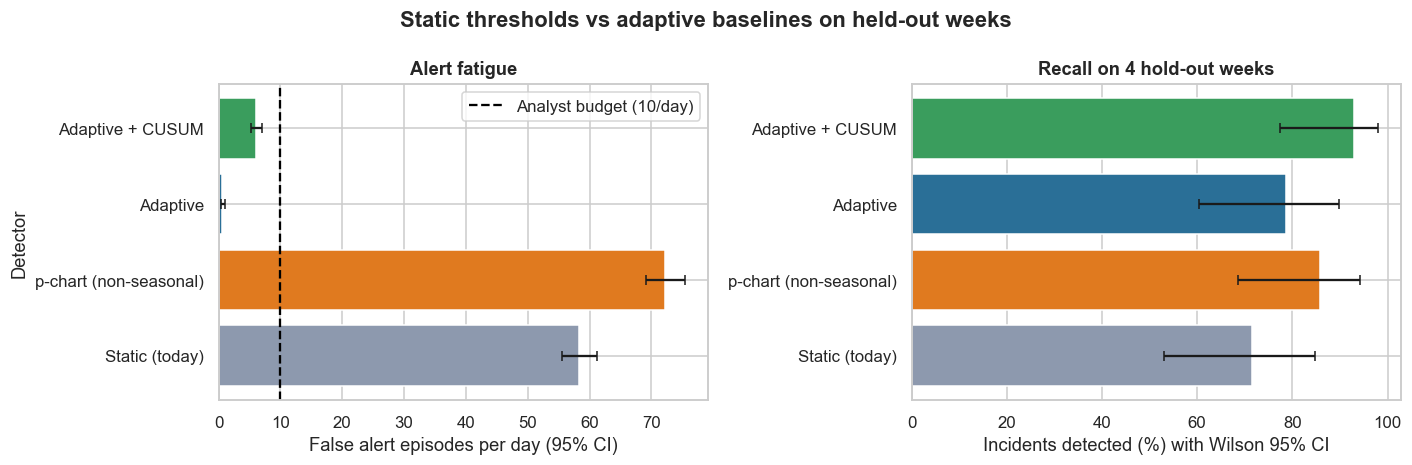

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
r_ = res.reset_index()
axes[0].barh(r_.detector, r_["false/day"], xerr=[r_["false/day"] - r_["false/day CI low"], r_["false/day CI high"] - r_["false/day"]], color=["#8d99ae", "#e07a1f", "#2a6f97", "#3a9d5d"], capsize=3)
axes[0].axvline(BUDGET, ls="--", color="black", label=f"Analyst budget ({BUDGET}/day)")
axes[0].set_xlabel("False alert episodes per day (95% CI)"); axes[0].set_ylabel("Detector"); axes[0].set_title("Alert fatigue"); axes[0].legend()
axes[1].barh(r_.detector, r_.recall * 100, xerr=[(r_.recall - r_["recall CI low"]) * 100, (r_["recall CI high"] - r_.recall) * 100], color=["#8d99ae", "#e07a1f", "#2a6f97", "#3a9d5d"], capsize=3)
axes[1].set_xlabel("Incidents detected (%) with Wilson 95% CI"); axes[1].set_ylabel(""); axes[1].set_title("Recall on 4 hold-out weeks")
plt.suptitle("Static thresholds vs adaptive baselines on held-out weeks", fontweight="bold"); plt.tight_layout(); plt.show()

**Takeaway:** the adaptive system sits comfortably inside the 10-a-day analyst budget, while static rules and the non-seasonal p-chart exceed it six- to sevenfold. On recall, adaptive + CUSUM is highest. The adaptive rule *without* CUSUM is the quietest (0.6 false alerts a day) but misses slow drifts, which is why the two layers belong together.

### 7.6 Where do the false alerts come from? (chi-square by time band)

**(a) Why?** If static alerts cluster at night and on festive days, that proves they are reacting to *normal seasonality*, not to incidents. This is the mechanism behind alert fatigue. We test whether the time-band mix of false alerts differs between detectors (chi-square test of independence, Cramér's V).

In [16]:
def band(tidx):
    h = ts.hour[tidx]; f = fest[tidx]
    return np.where(f, "festive day", np.where(h < 6, "night 00-06", np.where((h >= 18) & (h < 23), "evening peak 18-23", "daytime")))
fb = []
for n in ["Static (today)", "Adaptive + CUSUM"]:
    ep = DET[n][3]; tt = np.where(ep)[1]
    fb.append(pd.Series(band(tt)).value_counts().rename(n))
fb = pd.concat(fb, axis=1).fillna(0).astype(int)
chi2, p_b, dof, exp_ = stats.chi2_contingency(fb.values)
print(f"chi-square = {chi2:.1f}, dof = {dof}, p = {p_b:.2g}, min expected = {exp_.min():.1f}, Cramér's V = {np.sqrt(chi2 / (fb.values.sum() * (min(fb.shape) - 1))):.3f}")
(fb / fb.sum() * 100).round(1).assign(**{"static count": fb["Static (today)"], "adaptive count": fb["Adaptive + CUSUM"]})

chi-square = 240.3, dof = 3, p = 8.2e-52, min expected = 2.5, Cramér's V = 0.365


,Static (today),Adaptive + CUSUM,static count,adaptive count
festive day,42.300,25.300,691,43
daytime,33.100,33.500,541,57
evening peak 18-23,24.500,26.500,401,45
night 00-06,0.100,14.700,1,25


**(f) Observation:** the *timing* of false alerts differs strongly between the systems (χ² = 240, p ≈ 10⁻⁵², **Cramér's V = 0.37**, a medium-to-large association; one cell has an expected count of 2.5, acceptable under Cochran's rule because fewer than 20% of cells are below 5 and none is below 1). **42% of static false alerts fall on the 4 festive days** in the hold-out (14% of the time). The static rules are reacting to Diwali itself, not to incidents. The adaptive system's festive share drops to 25%. Static rules almost never fire at night only because their "≥ 20 attempts" guard silences them, which also blinds them to night-time incidents.

## 8. ML Section — Isolation Forest at a fixed alert budget

**Why:** the case says "ML models can supply thresholds". The most common unsupervised choice is the **Isolation Forest**, which scores how *isolated* a point is in feature space, with no labels needed. We give it the three standardised signals (−z_SR, z_latency, z_volume), so it can combine weak, simultaneous anomalies. We evaluate it **at the same alert budget** as the adaptive rule (Razorpay's "fixed alert volume" framing, also used in Case 3), so it can only win by catching more, not by alerting more. Default hyper-parameters; trained on the calibration week only (D-4-07).

In [17]:
feat = np.stack([-np.clip(z_sr, -10, 10), np.clip(z_lat, -10, 10), np.clip(z_vol, -10, 30)], axis=-1)
Xcal = feat[:, calib].reshape(-1, 3)
Xcal = Xcal[RNG.choice(len(Xcal), 60_000, replace=False)]
iso = IsolationForest(n_estimators=200, random_state=SEED).fit(Xcal)
score = -iso.score_samples(feat.reshape(-1, 3)).reshape(S, T)
target_windows = (adaptive_cusum & hold[None, :]).sum()
thr = np.quantile(score[:, hold], 1 - target_windows / (S * hold.sum()))
iso_alert = score >= thr
DET["Isolation Forest (same budget)"] = evaluate(iso_alert)
d_i, l_i, f_i, _ = DET["Isolation Forest (same budget)"]
print(f"Alert windows: adaptive+CUSUM {target_windows:,} vs IsolationForest {(iso_alert & hold[None, :]).sum():,}")
print(f"Isolation Forest: recall {d_i.mean():.2f}, false episodes/day {f_i / HOLD_DAYS:.1f}, median latency {np.nanmedian(l_i):.0f} min")
tab2 = np.array([[np.sum((d_a == 1) & (d_i == 1)), np.sum((d_a == 1) & (d_i == 0))], [np.sum((d_a == 0) & (d_i == 1)), np.sum((d_a == 0) & (d_i == 0))]])
print(f"McNemar adaptive+CUSUM vs IsolationForest: table {tab2.tolist()}, p = {mcnemar(tab2, exact=True).pvalue:.3f}")
pd.DataFrame({"type": inc_h.type, "Adaptive + CUSUM": d_a, "Isolation Forest": d_i}).groupby("type").mean().round(2)

Alert windows: adaptive+CUSUM 9,640 vs IsolationForest 9,640
Isolation Forest: recall 1.00, false episodes/day 267.0, median latency 5 min
McNemar adaptive+CUSUM vs IsolationForest: table [[26, 0], [2, 0]], p = 0.500


,Adaptive + CUSUM,Isolation Forest
type,,
card_testing,0.830,1.000
gateway_outage,1.000,1.000
latency_spike,1.000,1.000
merchant_failure,0.900,1.000
slow_degradation,1.000,1.000


**Takeaway:** at the same number of alerting windows (9,640), the Isolation Forest reaches 100% recall but produces **267 false alert *episodes* a day**, about 44× more tickets. Its alerts are scattered single windows, where the adaptive rules produce a few long, coherent episodes. The McNemar test on incidents shows no significant recall difference (p = 0.50; only 2 discordant incidents). **Interpretation:** an unsupervised model on standardised signals finds "unusual" windows, but unusual ≠ actionable. Without temporal persistence rules and a business budget on *tickets*, it simply rediscovers noise. Razorpay's design, where ML supplies thresholds inside a rule/CEP layer, is the sensible combination. ML should tune the baseline; it should not replace the alerting logic.

## 9. Business Translation — what the better detector is worth in ₹

**Step-by-step logic (hold-out, 48 series, 28 days):**
1. **Analyst cost** = alert episodes (true + false) × 10 minutes of triage × ₹1,000 per loaded analyst-hour.
2. **Revenue lost during incidents** = for each incident, the *excess failed payments* (expected successes − actual successes) from incident start until **detection + 5 minutes of mitigation** (rerouting), or until the incident ends if never detected, × average ticket ₹1,200 × (1 − 50% of customers who retry successfully anyway).
3. Annualise (× 365/28) and scale per 1,000 monitored series. Razorpay monitors far more.

**Assumptions (D-4-08):** ticket ₹1,200, retry recovery 50%, triage 10 min, analyst ₹1,000/hour, mitigation 5 min after the alarm. Sensitivity: ticket ₹800 / ₹1,600, retry 70% / 30%.

In [18]:
TICKET, RETRY, TRIAGE_MIN, ANALYST_HR, MITIGATE = 1200, 0.5, 10, 1000, 1
def lost_gmv(det, lat, ticket=TICKET, retry=RETRY):
    total = 0.0
    for (_, e), d_, l_ in zip(inc_h.iterrows(), det, lat):
        s0 = tpos[e.start]; s_end = tpos[e.end - pd.Timedelta(minutes=5)] + 1
        stop = min(s_end, s0 + int(l_ // 5) + MITIGATE) if d_ else s_end
        exp_succ = (A[e.sidx, s0:stop] * p_adj[e.sidx, s0:stop]); excess = np.clip(exp_succ - Y[e.sidx, s0:stop], 0, None)
        total += np.nansum(excess) * ticket * (1 - retry)
    return total
biz = []
for n, (det, lat, fa, _) in DET.items():
    alerts = fa + det.sum()
    an = alerts * TRIAGE_MIN / 60 * ANALYST_HR
    gm = lost_gmv(det, lat)
    biz.append((n, alerts, an, gm, an + gm))
biz = pd.DataFrame(biz, columns=["detector", "alert episodes (28d)", "analyst cost ₹", "lost GMV ₹", "total cost ₹"]).set_index("detector")
biz["total ₹ per year (×365/28)"] = biz["total cost ₹"] * 365 / 28
biz["per 1,000 series ₹ crore/yr"] = biz["total ₹ per year (×365/28)"] / S * 1000 / 1e7
base = biz.loc["Static (today)", "total cost ₹"]
biz["saving vs static"] = 1 - biz["total cost ₹"] / base
biz.round(1)

,alert episodes (28d),analyst cost ₹,lost GMV ₹,total cost ₹,total ₹ per year (×365/28),"per 1,000 series ₹ crore/yr",saving vs static
detector,,,,,,,
Static (today),1654,"275,666.700","2,046,117.200","2,321,783.800","30,266,110.700",63.100,0.000
p-chart (non-seasonal),2046,"341,000.000","1,460,823.400","1,801,823.400","23,488,055.100",48.900,0.200
Adaptive,40,"6,666.700","1,847,934.800","1,854,601.500","24,176,054.800",50.400,0.200
Adaptive + CUSUM,196,"32,666.700","1,664,774.400","1,697,441.100","22,127,357.200",46.100,0.300
Isolation Forest (same budget),7503,"1,250,500.000","1,468,849.300","2,719,349.300","35,448,660.600",73.900,-0.200


In [19]:
sens = []
for lab, tk, rt in [("Worst (ticket ₹800, retry 70%)", 800, 0.7), ("Base (₹1,200, 50%)", 1200, 0.5), ("Best (₹1,600, retry 30%)", 1600, 0.3)]:
    s_cost = DET["Static (today)"]; a_cost = DET["Adaptive + CUSUM"]
    cs_ = (s_cost[2] + s_cost[0].sum()) * TRIAGE_MIN / 60 * ANALYST_HR + lost_gmv(s_cost[0], s_cost[1], tk, rt)
    ca_ = (a_cost[2] + a_cost[0].sum()) * TRIAGE_MIN / 60 * ANALYST_HR + lost_gmv(a_cost[0], a_cost[1], tk, rt)
    sens.append((lab, cs_, ca_, cs_ - ca_, (cs_ - ca_) * 365 / 28 / S * 1000 / 1e7))
pd.DataFrame(sens, columns=["scenario", "static cost ₹ (28d)", "adaptive cost ₹ (28d)", "saving ₹ (28d, 48 series)", "saving ₹ crore/yr per 1,000 series"]).set_index("scenario").round(2)

,static cost ₹ (28d),adaptive cost ₹ (28d),"saving ₹ (28d, 48 series)","saving ₹ crore/yr per 1,000 series"
scenario,,,,
"Worst (ticket ₹800, retry 70%)","1,094,113.530","698,576.440","395,537.100",10.740
"Base (₹1,200, 50%)","2,321,783.840","1,697,441.100","624,342.740",16.960
"Best (₹1,600, retry 30%)","4,095,085.380","3,140,245.610","954,839.780",25.930


**Business reading:** - **Analyst cost (28 days, 48 lines):** ≈ ₹2.76 lakh (1,654 episodes) with static rules vs ≈ ₹0.33 lakh (196 episodes) adaptive, an **88% cut**. This is comparable to Razorpay's documented "about 80% cost reduction".
- **Revenue lost during incidents:** ₹20.5 lakh vs ₹16.6 lakh (−19%). The gain comes from catching merchant-specific failures and slow drifts that static rules never see. Outages are caught by both, a few minutes apart.
- **Total:** ≈ **₹6.2 lakh saved per 28 days on 48 lines**, i.e. **≈ ₹17 crore a year per 1,000 monitored lines** (range ₹11–26 crore across ticket size and retry assumptions). The bigger, harder-to-price benefit is **trust**: an on-call team that receives 6 alerts a day, 1 in 8 of them real, actually responds. One receiving 58 a day, 1 in 80 real, learns to ignore the pager.
- Lost-revenue figures use simulated attempts and our ₹1,200 ticket / 50% retry assumptions, so they are planning estimates.

## 10. Recommendation and Decision

**I recommend replacing static thresholds with the adaptive system, rolled out in shadow mode first.**

| Stage | Action | Exit criterion |
|---|---|---|
| 1. Shadow (2–4 weeks) | Run the adaptive detector alongside static alerts. Page only on static, but log both. Compare against post-mortems. | Adaptive catches every post-mortem incident static caught |
| 2. Switch | Page on adaptive. Keep static only as a catastrophic backstop (e.g., SR < 30%). | False alerts ≤ 10 a day; no missed P1 incident |
| 3. Pool | Add gateway- and issuer-level pooled detectors for sub-minute outage detection (streaming windows). | Median time-to-detect for outages < 1 minute |
| 4. Correlate | Group alerts sharing a gateway/issuer and time into one ticket. | Tickets per incident ≈ 1 |
| 5. Recalibrate | Monthly: re-estimate φ, re-check the alert budget, add new calendar events (sales, IPL finals). | Budget adherence |

**KPIs to monitor:** false alerts per day and per analyst-shift; alert precision; median and p90 time-to-detect by incident type; incidents found by post-mortem but missed by the detector (the true recall gap); revenue lost per incident; dispersion φ and autocorrelation drift by gateway.

## 11. Risks, Limitations and Next Steps

- **Synthetic data:** incident types and sizes are ours. Real incidents are messier (partial outages for one card BIN, an issuer bank down for UPI only). Recall on real data must be estimated from post-mortems, because the true incident list is never complete.
- **Baseline contamination:** the trailing 14-day baseline includes past incidents. We pool many days, so a short outage barely moves it, but a week-long degradation would slowly become "normal". Mitigation: exclude flagged windows from the baseline (robust re-estimation) and keep a 4-week reference.
- **Holiday calendar dependency:** the festive adjustment works because Dussehra precedes Diwali. A brand-new event (an IPL final, a flash sale) needs either a manual calendar entry or a fast-adapting component.
- **Latency of our windows:** 5-minute windows cap detection at about 5–10 minutes. Razorpay reports < 30 seconds using streaming (Flink). The same statistics apply to 30-second windows, but volumes per window shrink, so **pooling across merchants on a gateway** becomes essential (gateway-level z-scores).
- **Alert correlation:** a gateway outage fires on 16 series at once. Production systems should **group alerts by root cause** (gateway, issuer) into one ticket. That alone cuts analyst load further.
- **Next steps:** (1) a gateway-level pooled detector for sub-minute alerts; (2) sequence/CEP rules for card testing ("5 declines then a success" per card); (3) monthly re-calibration of φ and k against the alert budget; (4) track false alerts per analyst-shift and median time-to-detect as standing KPIs.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Adaptive expected SR | p̂ = Σ successes / Σ attempts over the trailing 14 days, same 5-min slot ± 1 (non-festive); festive: logit p̂ + δ_festive |
| Quasi-binomial z | z = (y − n p̂) / √(φ̂ n p̂ (1 − p̂)) |
| Dispersion | φ̂ = Pearson X² / df |
| Robust latency z | (log L − median) / (1.4826 · MAD) |
| CUSUM (lower) | S_t = max(0, S_{t−1} − z_t − k_ref), alarm when S_t > h (k_ref = 0.5, h = 8) |
| Ljung–Box | Q = n(n + 2) Σ_{k=1..h} ρ̂_k² / (n − k) ~ χ²(h) |
| Exact rate-ratio test | k_A | (k_A + k_S) ~ Binomial(k_A + k_S, 0.5) under H0 (equal exposure) |
| Poisson CI for count k | [χ²(0.025; 2k)/2, χ²(0.975; 2k + 2)/2] |

| Term | Meaning |
|---|---|
| Adaptive / calendar-aware baseline | "Normal" computed separately for each series, time of day and type of day. |
| Overdispersion | More variation than coin-flipping alone would produce. |
| Autocorrelation | Today's (this window's) value predicts the next one. |
| Alert episode | A run of consecutive alerting windows on one series, which counts as one ticket. |
| Recall | Share of real incidents detected. |
| Alert precision | Share of alerts that were real incidents. |
| CUSUM | A chart that adds up small deviations until they become significant, to catch slow drifts. |
| Isolation Forest | An unsupervised model that flags points that are easy to "isolate" from the rest. |
| Alert budget | The number of alerts a team can really investigate per day. Thresholds must respect it. |